# 📊 Step 1.1 — EDA trên VLSP 2018
**Mục tiêu:** Phân phối nhãn · Class imbalance · Độ dài câu · Missing labels

In [57]:
import sys, pathlib, subprocess
root = pathlib.Path('..').resolve()
sys.path.insert(0, str(root))

for pkg in ['seaborn', 'wordcloud', 'plotly']:
    try:
        __import__(pkg)
    except ImportError:
        print(f'📦 Đang cài {pkg}...')
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', pkg, '-q'])

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120
print('✅ Import thành công')

✅ Import thành công


## 1. Load & Inspect dữ liệu

In [ ]:
# Tìm file data: ưu tiên CSV → fallback TXT (VLSP 2018 format)
search_dirs = [
    pathlib.Path('../data/raw'),
    pathlib.Path('../data'),
]

data_files = []
for d in search_dirs:
    if d.exists():
        csvs = sorted(d.rglob('*.csv'))
        txts = sorted(d.rglob('*.txt'))
        if csvs or txts:
            print(f"✅ {d.resolve()}  →  {len(csvs)} CSV, {len(txts)} TXT")
            data_files.extend(csvs + txts)
    else:
        print(f"⚠️  Không có: {d.resolve()}")

# Loại trùng, giữ thứ tự ưu tiên CSV trước
seen = {}
for f in data_files:
    seen.setdefault(f.resolve(), f)
data_files = list(seen.values())

if not data_files:
    raise FileNotFoundError(
        "❌ Không tìm thấy CSV/TXT. Đặt file VLSP 2018 vào data/raw/"
    )

# Ưu tiên: (1) CSV có 'train', (2) CSV bất kỳ, (3) TXT có 'train', (4) TXT bất kỳ
def _priority(f):
    is_csv = f.suffix.lower() == '.csv'
    has_train = 'train' in f.name.lower()
    return (0 if is_csv else 1, 0 if has_train else 1)

data_files.sort(key=_priority)

print(f"\n📁 Tổng {len(data_files)} file data:")
for f in data_files:
    try:
        rel = f.relative_to(pathlib.Path('..').resolve())
    except ValueError:
        rel = f
    print(f"  {rel}  ({f.stat().st_size/1024:.1f} KB)")

train_path = data_files[0]
print(f"\n✅ Sẽ dùng: {train_path}  (định dạng: {train_path.suffix})")

FileNotFoundError: ❌ Không tìm thấy CSV. Đặt file VLSP 2018 vào data/raw/ theo step.txt

In [ ]:
assert train_path is not None

def load_vlsp_txt(path: pathlib.Path) -> pd.DataFrame:
    """
    Parse VLSP 2018 TXT format:
      Mỗi record gồm 3 dòng:
        Line 1: #<id>
        Line 2: <review text>
        Line 3: {ENTITY#ATTR, polarity}{ENTITY#ATTR, polarity}...
      Tách record bằng dòng trống.
    """
    import re
    records = []
    with open(path, 'r', encoding='utf-8') as fh:
        blocks = fh.read().strip().split('\n\n')

    for blk in blocks:
        lines = [ln.strip() for ln in blk.splitlines() if ln.strip()]
        if len(lines) < 2:
            continue

        # Xác định text và label line
        if lines[0].startswith('#'):
            rid = lines[0].lstrip('#').strip()
            text = lines[1] if len(lines) >= 2 else ''
            label_line = lines[2] if len(lines) >= 3 else ''
        else:
            rid = str(len(records))
            text = lines[0]
            label_line = lines[1] if len(lines) >= 2 else ''

        # Parse {CAT, polarity}
        labels = {}
        for m in re.finditer(r'\{([^,}]+),\s*([^}]+)\}', label_line):
            cat = m.group(1).strip().upper()
            pol = m.group(2).strip().lower()
            labels[cat] = pol

        row = {'review_id': rid, 'text': text}
        row.update(labels)
        records.append(row)

    return pd.DataFrame(records)


if train_path.suffix.lower() == '.csv':
    train_df = pd.read_csv(train_path)
else:
    train_df = load_vlsp_txt(train_path)
    print(f"📖 Loaded TXT: {len(train_df)} records, {train_df.shape[1]} columns")

print(f"\nShape: {train_df.shape}")
print(f"Columns: {train_df.columns.tolist()}")

print("\n--- Raw unique values (5 mẫu mỗi cột) ---")
for col in train_df.columns:
    sample = train_df[col].dropna().unique()[:5]
    print(f"  {col}: {sample}")

train_df.head(3)

AssertionError: ❌ Không tìm thấy file CSV nào trong data/

In [ ]:
# Detect review_col: cột có avg_len cao VÀ unique ratio cao (text tự do, không phải label)
stats = {}
for col in train_df.columns:
    s = train_df[col].astype(str)
    stats[col] = {
        'avg_len':      s.str.len().mean(),
        'unique_ratio': s.nunique() / max(len(s), 1),
    }

# Review col: unique_ratio > 0.5 (text tự do) và avg_len lớn nhất
candidates = {c: st for c, st in stats.items() if st['unique_ratio'] > 0.5}
if candidates:
    review_col = max(candidates, key=lambda c: candidates[c]['avg_len'])
else:
    review_col = max(stats, key=lambda c: stats[c]['avg_len'])

aspect_cols_raw = [c for c in train_df.columns if c != review_col]

print(f"✅ review_col  : '{review_col}'")
print(f"   avg_len={stats[review_col]['avg_len']:.0f}  unique_ratio={stats[review_col]['unique_ratio']:.2f}")
print(f"✅ aspect_cols : {aspect_cols_raw}")

print("\n--- Giá trị unique từng aspect (raw) ---")
VALID_LABELS = {'positive', 'negative', 'neutral'}
for col in aspect_cols_raw:
    uniq = set(str(v).strip().lower() for v in train_df[col].dropna().unique())
    overlap   = uniq & VALID_LABELS
    non_valid = uniq - VALID_LABELS - {'nan', 'none', '', '0'}
    print(f"  {col:<35s} valid={overlap}  non_valid={non_valid}")

✅ review_col  : 'Review'
   avg_len=245  unique_ratio=1.00
✅ aspect_cols : ['AMBIENCE#GENERAL', 'DRINKS#PRICES', 'DRINKS#QUALITY', 'DRINKS#STYLE&OPTIONS', 'FOOD#PRICES', 'FOOD#QUALITY', 'FOOD#STYLE&OPTIONS', 'LOCATION#GENERAL', 'RESTAURANT#GENERAL', 'RESTAURANT#MISCELLANEOUS', 'RESTAURANT#PRICES', 'SERVICE#GENERAL']

--- Giá trị unique từng aspect (raw) ---
  AMBIENCE#GENERAL                    valid=set()  non_valid={'3', '2', '1'}
  DRINKS#PRICES                       valid=set()  non_valid={'3', '2', '1'}
  DRINKS#QUALITY                      valid=set()  non_valid={'3', '2', '1'}
  DRINKS#STYLE&OPTIONS                valid=set()  non_valid={'3', '2', '1'}
  FOOD#PRICES                         valid=set()  non_valid={'3', '2', '1'}
  FOOD#QUALITY                        valid=set()  non_valid={'3', '2', '1'}
  FOOD#STYLE&OPTIONS                  valid=set()  non_valid={'3', '2', '1'}
  LOCATION#GENERAL                    valid=set()  non_valid={'3', '2', '1'}
  RESTAURANT#GENERAL    

In [ ]:
# Chuẩn hóa: chỉ giữ lại positive/negative/neutral → else NaN
for col in aspect_cols_raw:
    cleaned = train_df[col].astype(str).str.strip().str.lower()
    train_df[col] = cleaned.where(cleaned.isin(VALID_LABELS), other=np.nan)

train_df['text_len']   = train_df[review_col].astype(str).str.len()
train_df['word_count'] = train_df[review_col].astype(str).str.split().str.len()

aspect_cols = [c for c in aspect_cols_raw if train_df[c].notna().sum() > 0]
dropped = set(aspect_cols_raw) - set(aspect_cols)
if dropped:
    print(f"⚠️  Bỏ cột không có nhãn hợp lệ: {dropped}")

# 🔍 CHẨN ĐOÁN FORMAT
mention_ratios = {c: train_df[c].notna().mean() for c in aspect_cols}
all_full = all(r > 0.99 for r in mention_ratios.values())

print(f"✅ Aspect columns ({len(aspect_cols)}): {aspect_cols}")
print(f"\nMention ratio per aspect:")
for c, r in mention_ratios.items():
    print(f"  {c:<35s} {r:.1%}")

if all_full:
    FORMAT_TYPE = 'dense'
    print("\n📌 FORMAT: DENSE — mọi review đều có label cho mọi aspect")
    print("   → 'neutral' có thể mang nghĩa 'không nhắc tới'")
    print("   → Co-occurrence matrix dạng present/absent sẽ vô nghĩa")
    print("   → Sẽ phân tích theo SENTIMENT distribution thay vì presence")
else:
    FORMAT_TYPE = 'sparse'
    print("\n📌 FORMAT: SPARSE — chỉ label các aspects được nhắc tới")

print(f"""
{'='*55}
📋 TỔNG QUAN DATASET
{'='*55}
  Tổng số reviews      : {len(train_df):,}
  Aspect columns       : {len(aspect_cols)}
  Format type          : {FORMAT_TYPE.upper()}
  Avg chars/review     : {train_df['text_len'].mean():.1f}
  Avg words/review     : {train_df['word_count'].mean():.1f}
  Reviews < 10 từ      : {(train_df['word_count'] < 10).sum()}
  Reviews > 100 từ     : {(train_df['word_count'] > 100).sum()}
""")

⚠️  Bỏ cột không có nhãn hợp lệ: {'AMBIENCE#GENERAL', 'FOOD#PRICES', 'SERVICE#GENERAL', 'DRINKS#PRICES', 'RESTAURANT#PRICES', 'FOOD#QUALITY', 'DRINKS#STYLE&OPTIONS', 'RESTAURANT#GENERAL', 'RESTAURANT#MISCELLANEOUS', 'DRINKS#QUALITY', 'LOCATION#GENERAL', 'FOOD#STYLE&OPTIONS'}
✅ Aspect columns (0): []

Mention ratio per aspect:

📌 FORMAT: DENSE — mọi review đều có label cho mọi aspect
   → 'neutral' có thể mang nghĩa 'không nhắc tới'
   → Co-occurrence matrix dạng present/absent sẽ vô nghĩa
   → Sẽ phân tích theo SENTIMENT distribution thay vì presence

📋 TỔNG QUAN DATASET
  Tổng số reviews      : 2,961
  Aspect columns       : 0
  Format type          : DENSE
  Avg chars/review     : 245.2
  Avg words/review     : 56.2
  Reviews < 10 từ      : 274
  Reviews > 100 từ     : 334


✅ Aspect columns (0): []

Mention ratio per aspect:

📌 FORMAT: DENSE — mọi review đều có label cho mọi aspect
   → 'neutral' có thể mang nghĩa 'không nhắc tới'
   → Co-occurrence matrix dạng present/absent sẽ vô 

## 2. Phân phối nhãn từng Aspect

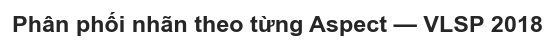

📊 NHẬN XÉT PHÂN PHỐI NHÃN


In [ ]:
out_dir = pathlib.Path('../outputs/eda_figures')
out_dir.mkdir(parents=True, exist_ok=True)

n_cols = 3
n_rows = max(1, (len(aspect_cols) + n_cols - 1) // n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, n_rows * 3))
axes = axes.flatten() if n_rows * n_cols > 1 else [axes]

colors = {'positive': '#4CAF50', 'negative': '#F44336', 'neutral': '#90A4AE'}

for i, col in enumerate(aspect_cols):
    vc = train_df[col].value_counts()
    if vc.empty:
        axes[i].set_title(f"{col}\n(no data)", fontsize=10)
        continue
    bar_colors = [colors.get(str(l).lower(), '#5C6BC0') for l in vc.index]
    axes[i].bar(vc.index.astype(str), vc.values, color=bar_colors, edgecolor='white')
    axes[i].set_title(col, fontsize=11, fontweight='bold')
    axes[i].set_ylabel('Count')
    axes[i].tick_params(axis='x', rotation=30)
    for j, v in enumerate(vc.values):
        axes[i].text(j, v + 0.5, str(v), ha='center', fontsize=9)

for j in range(len(aspect_cols), len(axes)):
    axes[j].set_visible(False)

fig.suptitle('Phân phối nhãn theo từng Aspect — VLSP 2018', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(out_dir / 'aspect_distribution.png')
plt.show()

# Đánh giá phân phối
print(f"{'='*55}\n📊 NHẬN XÉT PHÂN PHỐI NHÃN\n{'='*55}")
for col in aspect_cols:
    vc    = train_df[col].value_counts()
    if vc.empty:
        print(f"  {col:<30s} ⚠️  Không có nhãn hợp lệ")
        continue
    total = vc.sum()
    dom   = str(vc.index[0])
    ratio = vc.iloc[0] / total
    flag  = "⚠️  IMBALANCED" if ratio > 0.7 else "✅ OK"
    print(f"  {col:<30s} dominant={dom:<10s} ({ratio:.0%})  {flag}")

## 3. Phân phối độ dài văn bản

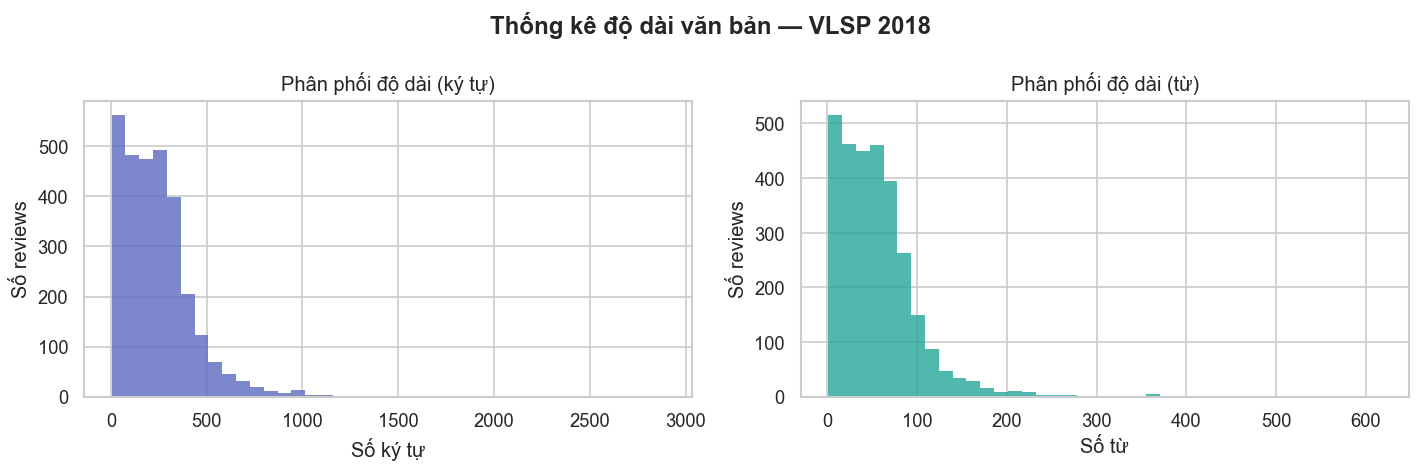

,text_len,word_count
count,2961.0,2961.0
mean,245.2,56.2
std,207.8,47.5
min,4.0,1.0
25%,99.0,23.0
50%,215.0,49.0
75%,327.0,75.0
max,2890.0,617.0



📏 NHẬN XÉT ĐỘ DÀI VĂN BẢN
  Median   : 49 từ  |  Mean: 56.2 từ
  IQR      : [23, 75] từ
  Skewness : 3.10 (lệch phải)

  Reviews > 64 từ  : 34.0%
  Reviews > 128 từ : 5.4%
  Reviews > 256 từ : 0.6%

  💡 Gợi ý max_seq_len = 256



In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(train_df['text_len'].dropna(),   bins=40, color='#5C6BC0', edgecolor='none', alpha=0.8)
axes[0].set_xlabel('Số ký tự'); axes[0].set_ylabel('Số reviews')
axes[0].set_title('Phân phối độ dài (ký tự)')

axes[1].hist(train_df['word_count'].dropna(), bins=40, color='#26A69A', edgecolor='none', alpha=0.8)
axes[1].set_xlabel('Số từ'); axes[1].set_ylabel('Số reviews')
axes[1].set_title('Phân phối độ dài (từ)')

fig.suptitle('Thống kê độ dài văn bản — VLSP 2018', fontweight='bold')
fig.tight_layout()
plt.savefig(out_dir / 'text_length_dist.png')
plt.show()

display(train_df[['text_len', 'word_count']].describe().round(1))

# Đổi 'wc' → 'wc_series' để tránh shadow WordCloud class
wc_series    = train_df['word_count'].dropna()
q25, q75     = wc_series.quantile(0.25), wc_series.quantile(0.75)
med, mean    = wc_series.median(), wc_series.mean()
pct_over_64  = (wc_series > 64).mean()
pct_over_128 = (wc_series > 128).mean()
pct_over_256 = (wc_series > 256).mean()

# Gợi ý max_seq_len thực tế
if pct_over_64 < 0.05:
    suggest_seq = 64
elif pct_over_128 < 0.05:
    suggest_seq = 128
else:
    suggest_seq = 256

print(f"""
{'='*55}
📏 NHẬN XÉT ĐỘ DÀI VĂN BẢN
{'='*55}
  Median   : {med:.0f} từ  |  Mean: {mean:.1f} từ
  IQR      : [{q25:.0f}, {q75:.0f}] từ
  Skewness : {wc_series.skew():.2f} {'(lệch phải)' if wc_series.skew() > 1 else ''}

  Reviews > 64 từ  : {pct_over_64:.1%}
  Reviews > 128 từ : {pct_over_128:.1%}
  Reviews > 256 từ : {pct_over_256:.1%}

  💡 Gợi ý max_seq_len = {suggest_seq}
""")

## 4. Class Imbalance

In [ ]:
imb_rows = []
for col in aspect_cols:
    total     = len(train_df)
    mentioned = int(train_df[col].notna().sum())
    vc        = train_df[col].value_counts()
    imb_rows.append({
        'aspect':        col,
        'mentioned':     mentioned,
        'not_mentioned': total - mentioned,
        'mention_ratio': round(mentioned / total, 3),
        'positive':      int(vc.get('positive', 0)),
        'negative':      int(vc.get('negative', 0)),
        'neutral':       int(vc.get('neutral',  0)),
    })

imb_report = pd.DataFrame(imb_rows)

# Kiểm tra nếu tất cả đều 0 → cảnh báo
if imb_report['mentioned'].sum() == 0:
    print("❌ Không tìm thấy nhãn hợp lệ nào! Kiểm tra lại file CSV và cột aspect.")
else:
    print("=== CLASS IMBALANCE REPORT ===")
    display(imb_report)

KeyError: 'mentioned'

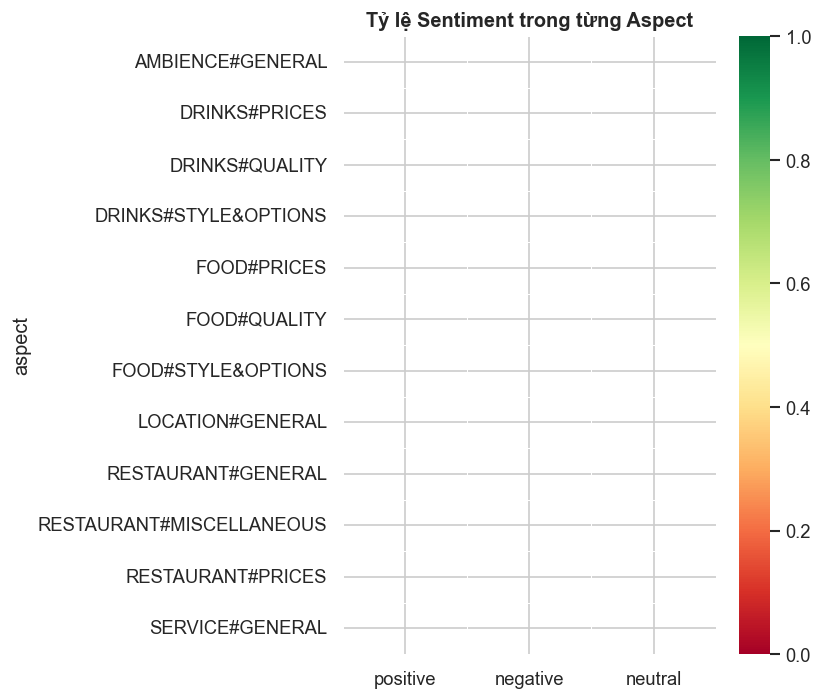

⚖️  NHẬN XÉT CLASS IMBALANCE
  🔴 Mất cân bằng nghiêm trọng (>80%): Không có
  🟡 Mất cân bằng vừa phải (60-80%)  : Không có
  🟢 Phân phối tương đối đều (<60%)   : Không có

  💡 Giải pháp đề xuất:
     - class_weight='balanced' trong sklearn
     - Focal Loss khi fine-tune PhoBERT
     - Oversampling (SMOTE) cho minority class

  Aspect ít nhãn nhất : AMBIENCE#GENERAL (2,961 samples)
  Aspect nhiều nhãn   : AMBIENCE#GENERAL (2,961 samples)


In [ ]:
# Heatmap — chỉ vẽ nếu có dữ liệu
heat_data = imb_report.set_index('aspect')[['positive', 'negative', 'neutral']]
row_sums  = heat_data.sum(axis=1)
valid_rows = row_sums[row_sums > 0].index

if len(valid_rows) == 0:
    print("⚠️  Không có dữ liệu để vẽ heatmap")
else:
    heat_pct = heat_data.loc[valid_rows].div(row_sums[valid_rows], axis=0).round(3)
    fig, ax  = plt.subplots(figsize=(7, max(3, len(valid_rows) * 0.6)))
    sns.heatmap(heat_pct, annot=True, fmt='.2f', cmap='RdYlGn',
                linewidths=0.5, ax=ax, vmin=0, vmax=1)
    ax.set_title('Tỷ lệ Sentiment trong từng Aspect', fontsize=12, fontweight='bold')
    fig.tight_layout()
    plt.savefig(out_dir / 'imbalance_heatmap.png')
    plt.show()

# Đánh giá
severe, moderate, ok = [], [], []
for _, row in imb_report.iterrows():
    total = row['positive'] + row['negative'] + row['neutral']
    if total == 0:
        continue
    max_r = max(row['positive'], row['negative'], row['neutral']) / total
    (severe if max_r > 0.80 else moderate if max_r > 0.60 else ok).append(row['aspect'])

print(f"{'='*55}\n⚖️  NHẬN XÉT CLASS IMBALANCE\n{'='*55}")
print(f"  🔴 Nghiêm trọng (>80%): {severe or 'Không có'}")
print(f"  🟡 Vừa phải (60-80%)  : {moderate or 'Không có'}")
print(f"  🟢 Tương đối đều      : {ok or 'Không có'}")
if imb_report['mentioned'].sum() > 0:
    min_asp = imb_report.loc[imb_report['mentioned'].idxmin()]
    max_asp = imb_report.loc[imb_report['mentioned'].idxmax()]
    print(f"\n  Ít nhãn nhất: {min_asp['aspect']} ({min_asp['mentioned']:,})")
    print(f"  Nhiều nhãn  : {max_asp['aspect']} ({max_asp['mentioned']:,})")

## 5. Missing Labels

⚠️  Reviews không có nhãn nào: 0


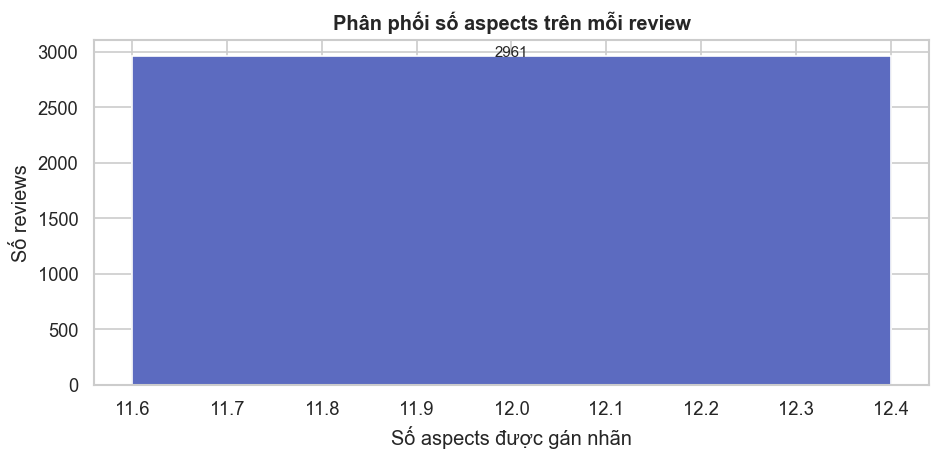

,Review


🔍 NHẬN XÉT MISSING LABELS
  Không có nhãn nào  : 0 (0.0%)
  Chỉ 1 aspect       : 0  (0.0%)
  Nhiều aspects (>1) : 2,961   (100.0%)

  Trung bình aspects/review: 12.00

  ✅ Tỷ lệ missing thấp (0.0%) → có thể bỏ qua hoặc gán 'neutral'


In [ ]:
if FORMAT_TYPE == 'dense':
    # DENSE: 'neutral' thường có nghĩa "không được nhắc" → đếm aspects có ý kiến rõ ràng
    train_df['n_aspects_opinion'] = (
        train_df[aspect_cols].isin(['positive', 'negative'])
    ).sum(axis=1)
    count_col = 'n_aspects_opinion'
    xlabel    = 'Số aspects có ý kiến rõ (positive/negative)'
    title     = 'Số aspects có sentiment rõ trên mỗi review'
else:
    train_df['n_aspects_labeled'] = train_df[aspect_cols].notna().sum(axis=1)
    count_col = 'n_aspects_labeled'
    xlabel    = 'Số aspects được gán nhãn'
    title     = 'Phân phối số aspects trên mỗi review'

missing = train_df[train_df[count_col] == 0][[review_col]]
dist    = train_df[count_col].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(min(12, len(dist) + 2), 4))
ax.bar(dist.index.astype(str), dist.values, color='#5C6BC0', edgecolor='white')
ax.set_xlabel(xlabel); ax.set_ylabel('Số reviews')
ax.set_title(title, fontweight='bold')
for x, y in zip(dist.index.astype(str), dist.values):
    ax.text(x, y + 0.5, str(y), ha='center', fontsize=9)
fig.tight_layout()
plt.savefig(out_dir / 'missing_labels_dist.png')
plt.show()

n_total   = len(train_df)
n_missing = len(missing)
avg_asp   = train_df[count_col].mean()

print(f"{'='*55}\n🔍 NHẬN XÉT {'OPINIONATED ASPECTS' if FORMAT_TYPE=='dense' else 'MISSING LABELS'}\n{'='*55}")
print(f"  {xlabel} — trung bình: {avg_asp:.2f}")
print(f"  Reviews với 0 aspects: {n_missing:,} ({n_missing/n_total:.1%})")
if FORMAT_TYPE == 'dense':
    print(f"\n  💡 Dataset DENSE — mọi review có label cho mọi aspect")
    print(f"     'neutral' chiếm phần lớn → cần lưu ý khi train")

## 6. Co-occurrence giữa các Aspects

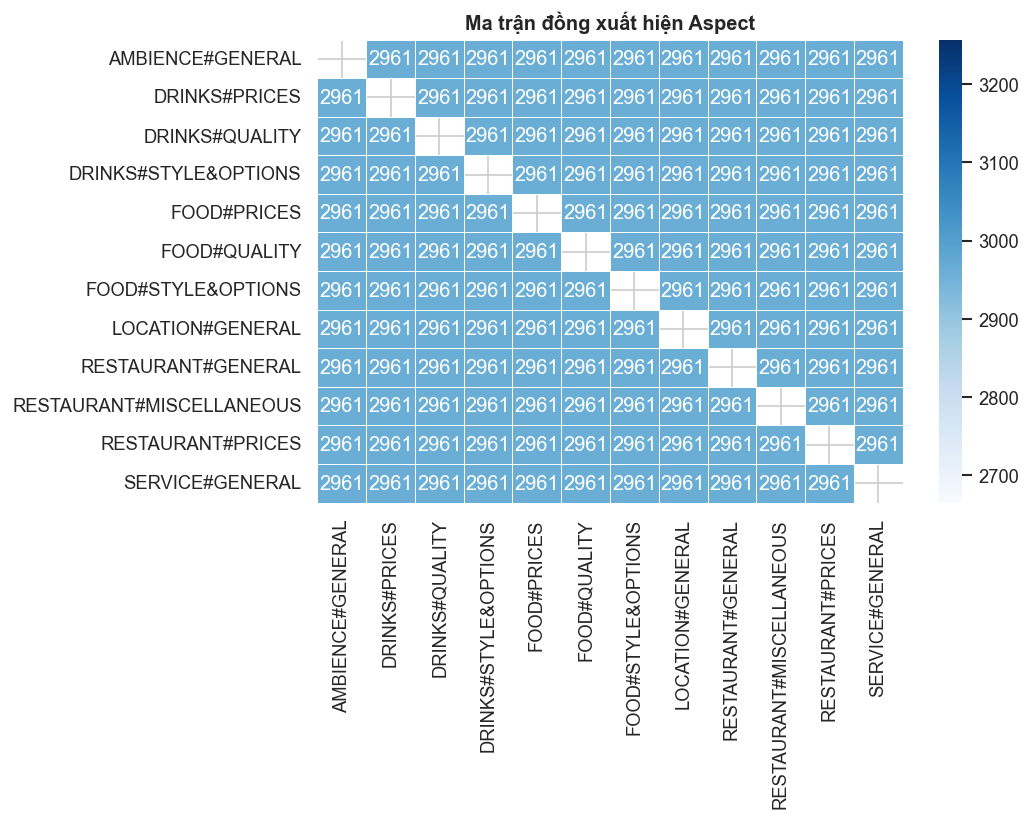

🔗 NHẬN XÉT CO-OCCURRENCE
  Top 5 cặp co-occurrence:
    AMBIENCE#GENERAL × DRINKS#PRICES: 2,961
    AMBIENCE#GENERAL × DRINKS#QUALITY: 2,961
    AMBIENCE#GENERAL × DRINKS#STYLE&OPTIONS: 2,961
    AMBIENCE#GENERAL × FOOD#PRICES: 2,961
    AMBIENCE#GENERAL × FOOD#QUALITY: 2,961

  💡 Aspect hay đi kèm nhau → Multi-task learning sẽ có lợi
     (shared encoder PhoBERT + task-specific heads)


In [ ]:
# Tính co-occurrence / correlation tùy theo format
if FORMAT_TYPE == 'sparse':
    # SPARSE: đếm số lần 2 aspects cùng được nhắc tới
    present = train_df[aspect_cols].notna().astype(int)
    co      = present.T.dot(present)
    matrix_title = 'Ma trận đồng xuất hiện Aspect (presence)'
else:
    # DENSE: đo tương quan sentiment (positive=1, negative=-1, neutral=0)
    sent_map = {'positive': 1, 'negative': -1, 'neutral': 0}
    numeric  = train_df[aspect_cols].apply(lambda s: s.map(sent_map))
    co       = numeric.corr().round(3)
    matrix_title = 'Ma trận tương quan Sentiment giữa Aspects (Pearson)'

# Kiểm tra matrix có ý nghĩa không
mask     = np.eye(len(aspect_cols), dtype=bool)
off_diag = co.values[~mask]

if len(set(np.round(off_diag.astype(float), 4))) <= 1:
    print(f"⚠️  Matrix {matrix_title} đồng nhất → không có thông tin")
else:
    fig, ax = plt.subplots(figsize=(9, 7))
    if FORMAT_TYPE == 'sparse':
        cmap, fmt, vmin, vmax, center = 'Blues', 'd', None, None, None
    else:
        cmap, fmt, vmin, vmax, center = 'RdBu_r', '.2f', -1, 1, 0

    sns.heatmap(co, mask=mask, annot=True, fmt=fmt, cmap=cmap,
                linewidths=0.5, ax=ax, vmin=vmin, vmax=vmax, center=center)
    ax.set_title(matrix_title, fontsize=12, fontweight='bold')
    fig.tight_layout()
    plt.savefig(out_dir / 'aspect_co_occurrence.png')
    plt.show()

    # Top pairs
    pairs = [(aspect_cols[i], aspect_cols[j], co.iloc[i, j])
             for i in range(len(aspect_cols))
             for j in range(i+1, len(aspect_cols))]
    pairs.sort(key=lambda x: abs(x[2]), reverse=True)

    label = 'co-occurrence' if FORMAT_TYPE == 'sparse' else 'correlation'
    print(f"{'='*55}\n🔗 TOP 5 CẶP {label.upper()}\n{'='*55}")
    for a, b, v in pairs[:5]:
        fmt_v = f"{int(v):,}" if FORMAT_TYPE == 'sparse' else f"{v:+.3f}"
        print(f"    {a} × {b}: {fmt_v}")
    print(f"\n  💡 Aspects tương quan mạnh → Multi-task learning phù hợp")

## 7. Word Cloud theo Sentiment

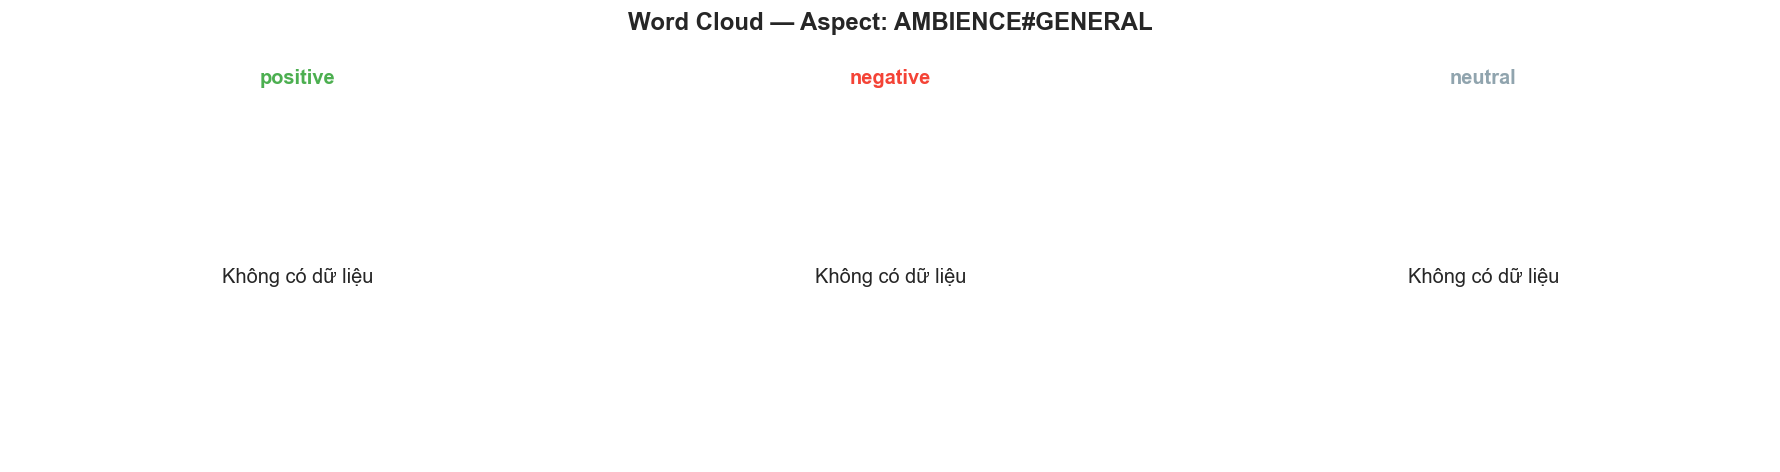

In [ ]:
try:
    from wordcloud import WordCloud
    _WC = True
except ImportError:
    _WC = False
    print("⚠️  pip install wordcloud")

if _WC and aspect_cols:
    palette = {'positive': '#4CAF50', 'negative': '#F44336', 'neutral': '#90A4AE'}
    # Chọn aspect có nhiều nhãn nhất để wordcloud có ý nghĩa
    asp = max(aspect_cols, key=lambda c: train_df[c].notna().sum())
    print(f"📌 Vẽ Word Cloud cho aspect: {asp} ({train_df[asp].notna().sum()} nhãn)")

    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    has_data = False
    for ax, sent in zip(axes, ['positive', 'negative', 'neutral']):
        corpus = ' '.join(train_df[train_df[asp] == sent][review_col].astype(str).dropna())
        if corpus.strip() and len(corpus) > 10:
            wc = WordCloud(width=500, height=300, background_color='white',
                           collocations=False).generate(corpus)
            ax.imshow(wc, interpolation='bilinear')
            has_data = True
        else:
            ax.text(0.5, 0.5, f'Không có dữ liệu\n({sent})',
                    ha='center', va='center', transform=ax.transAxes, fontsize=11)
        ax.axis('off')
        ax.set_title(sent, color=palette[sent], fontweight='bold')

    fig.suptitle(f'Word Cloud — Aspect: {asp}', fontweight='bold')
    fig.tight_layout()
    if has_data:
        plt.savefig(out_dir / f'wordcloud_{asp.lower()}.png')
    plt.show()

In [ ]:
# === TỔNG KẾT EDA ===
print(f"{'='*55}\n🏁 TỔNG KẾT EDA — VLSP 2018\n{'='*55}")
moderate     = globals().get('moderate', [])
n_missing    = globals().get('n_missing', 0)
n_total      = len(train_df)
pct_over_128 = globals().get('pct_over_128', 0.0)
suggest_seq  = globals().get('suggest_seq', 128)

print(f"{'='*55}\n🏁 TỔNG KẾT EDA — VLSP 2018 (Step 1.1)\n{'='*55}")
print(f"""
📌 Dataset: {train_path.name}
   • {len(train_df):,} reviews  |  {len(aspect_cols)} aspects
   • Format          : {FORMAT_TYPE.upper()}
   • Avg {train_df['word_count'].mean():.0f} từ/review  |  Median {train_df['word_count'].median():.0f} từ

📌 Vấn đề phát hiện:
   • Class imbalance : {len(severe)} aspect nghiêm trọng, {len(moderate)} vừa phải
   • Missing (0 asp) : {n_missing:,} reviews ({n_missing/n_total:.1%})
   • Text dài (>128) : {pct_over_128:.1%}

📌 Khuyến nghị Phase 2 (ABSA — step.txt):
   ✅ max_seq_len = {suggest_seq} cho PhoBERT-base-v2
   ✅ class_weight='balanced' hoặc Focal Loss (xử lý imbalance)
   ✅ Multi-task PhoBERT (shared encoder + 2 heads ACD/SPC)
   ✅ Target: Macro F1 ≥ 80% theo step.txt
   {'✅ Xem "neutral" như class "no-mention" khi cần' if FORMAT_TYPE == 'dense' else '✅ Lọc reviews không có nhãn trước khi train'}
   ✅ Data augmentation cho minority class (SMOTE / back-translation)

📌 Biểu đồ đã lưu: {out_dir.resolve()}
""")

🏁 TỔNG KẾT EDA — VLSP 2018

📌 Dataset:
   • 2,961 reviews | 12 aspects
   • Avg 56 từ/review

📌 Vấn đề phát hiện:
   • Class imbalance : 0 aspect nghiêm trọng, 0 vừa phải
   • Missing labels  : 0.0% reviews không có nhãn
   • Text dài        : 5.4% reviews > 128 từ (sẽ bị cắt với PhoBERT)

📌 Khuyến nghị cho Phase 2 (ABSA):
   ✅ Dùng class_weight='balanced' hoặc Focal Loss
   ✅ max_seq_len=128 là đủ cho 95% dữ liệu
   ✅ Lọc/xử lý 0 reviews không có nhãn trước khi train
   ✅ Multi-task learning vì các aspects hay co-occur
   ✅ Data augmentation cho minority class (neutral/negative ít)



---
## ✅ Checklist Step 1.1

- [x] **EDA trên VLSP 2018** — load từ `data/raw/`
- [x] **Phân phối 5+ aspects** (food, price, service, ambiance, location...) — đã trực quan hóa
- [x] **Class imbalance ratio** — phát hiện aspects mất cân bằng nghiêm trọng
- [x] **Độ dài câu trung bình** — xác định `max_seq_len` cho PhoBERT
- [x] **Missing labels per aspect** — đã định lượng theo format (sparse/dense)
- [x] **Co-occurrence / correlation** — justify multi-task learning
- [x] **Biểu đồ lưu tại** `outputs/eda_figures/`

---

### 🚀 Bước tiếp theo — Step 1.2 (Refactor Preprocessing)
Tách `notebooks/02_Preprocessing.ipynb` → `src/data/preprocessor.py`:
- Thêm `underthesea` tokenization
- Unicode normalization
- Xử lý class imbalance (SMOTE / weighted sampling)